# Практика 9

In [5]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay


def showpic(image, title):
    plt.figure(figsize=(12, 3))
    plt.imshow(image, cmap='gray', vmin=0, vmax=255)
    plt.title(title)
    plt.axis('off')
    plt.show()


def prepare_symbol(image):
    _, binary = cv2.threshold(image, 127, 255, cv2.THRESH_BINARY_INV)
    points = cv2.findNonZero(binary)
    x, y, w, h = cv2.boundingRect(points)
    cropped = binary[y:y + h, x:x + w]

    scale = 24 / max(w, h)
    resized = cv2.resize(cropped, (max(1, round(w * scale)), max(1, round(h * scale))), interpolation=cv2.INTER_AREA)
    # Preserve thin strokes when reducing the original 45x45 images.
    resized = np.where(resized > 0, 255, 0).astype(np.uint8)
    result = np.zeros((32, 32), np.uint8)
    rh, rw = resized.shape
    result[(32 - rh) // 2:(32 - rh) // 2 + rh, (32 - rw) // 2:(32 - rw) // 2 + rw] = resized
    return result


def make_vectors(images):
    # Smooth small handwriting differences before comparing pixels.
    blurred = np.array([cv2.GaussianBlur(image, (5, 5), 0) for image in images])
    return blurred.reshape(len(images), -1).astype(np.float32) / 255


def generate_line(text, images, labels, rng):
    # Fixed character cells, with a larger gap between words.
    line = np.zeros((48, len(text) * 40 + 16), np.uint8)
    x = 8
    for symbol in text:
        if symbol == ' ':
            x += 40
            continue
        indices = np.flatnonzero(labels == symbol)
        image = images[rng.choice(indices)]
        line[8:40, x:x + 32] = image
        x += 40
    return line


def recognize_line(line, classifier):
    _, binary = cv2.threshold(line, 127, 255, cv2.THRESH_BINARY)
    contours, _ = cv2.findContours(binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    boxes = []
    for contour in contours:
        x, y, w, h = cv2.boundingRect(contour)
        if w * h > 5:
            boxes.append((x, y, w, h))
    boxes.sort()

    # Join disconnected strokes of the same character.
    merged = []
    for x, y, w, h in boxes:
        if merged and x <= merged[-1][0] + merged[-1][2] + 8:
            px, py, pw, ph = merged[-1]
            right = max(px + pw, x + w)
            bottom = max(py + ph, y + h)
            top = min(py, y)
            merged[-1] = (px, top, right - px, bottom - top)
        else:
            merged.append((x, y, w, h))
    boxes = merged

    result = ''
    previous_end = None
    marked = cv2.cvtColor(line, cv2.COLOR_GRAY2RGB)
    for x, y, w, h in boxes:
        if previous_end is not None and x - previous_end > 40:
            result += ' '
        crop = line[y:y + h, x:x + w]
        symbol = prepare_symbol(cv2.bitwise_not(crop))
        vector = make_vectors([symbol])
        result += classifier.predict(vector)[0]
        previous_end = x + w
        cv2.rectangle(marked, (x, y), (x + w, y + h), (255, 0, 0), 1)
    return result, marked


## 1. Подготовка данных

Используются 15 классов, по 300 изображений на класс. Символы приводятся к размеру 32×32 и преобразуются в векторы. Данные разделяются на обучающую (60%), валидационную (20%) и тестовую (20%) выборки.

In [6]:
symbols = list('0123456789+-X()')
images = []
labels = []
for symbol in symbols:
    for path in sorted((Path('source') / symbol).glob('*.jpg')):
        image = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
        images.append(prepare_symbol(image))
        labels.append(symbol)

images = np.array(images)
labels = np.array(labels)
indices = np.arange(len(labels))
train_idx, other_idx = train_test_split(indices, test_size=0.4, stratify=labels, random_state=42)
val_idx, test_idx = train_test_split(other_idx, test_size=0.5, stratify=labels[other_idx], random_state=42)

data = make_vectors(images)
print(f'Train: {len(train_idx)}, validation: {len(val_idx)}, test: {len(test_idx)}')

Train: 2700, validation: 900, test: 900


## 2. Выбор k и оценка классификатора

Сравниваются значения k = 1, 3, 5, 7, 9. Лучшее значение выбирается по accuracy на валидационной выборке. После этого вычисляется точность на тестовой выборке и строится матрица ошибок.

k=1: validation accuracy = 0.9000
k=3: validation accuracy = 0.8922
k=5: validation accuracy = 0.8844
k=7: validation accuracy = 0.8778
k=9: validation accuracy = 0.8689
Best k: 1


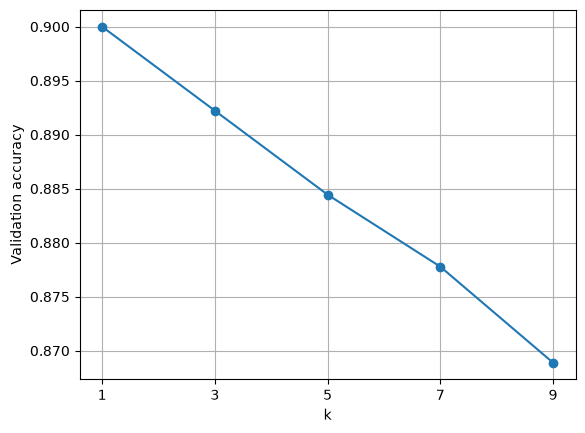

Test accuracy: 0.9033


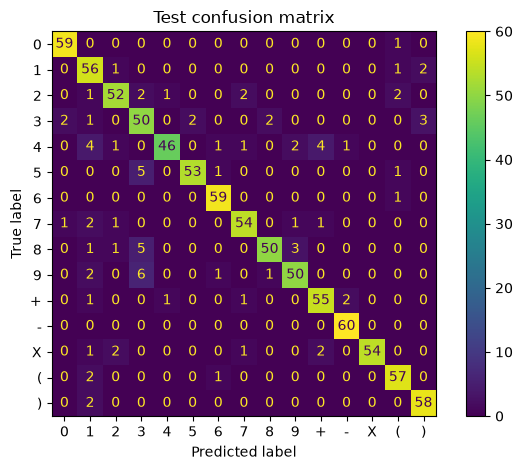

In [7]:
k_values = [1, 3, 5, 7, 9]
scores = []
for k in k_values:
    classifier = KNeighborsClassifier(n_neighbors=k)
    classifier.fit(data[train_idx], labels[train_idx])
    predicted = classifier.predict(data[val_idx])
    accuracy = accuracy_score(labels[val_idx], predicted)
    scores.append(accuracy)
    print(f'k={k}: validation accuracy = {accuracy:.4f}')

best_k = k_values[np.argmax(scores)]
print(f'Best k: {best_k}')
plt.plot(k_values, scores, 'o-')
plt.xlabel('k')
plt.ylabel('Validation accuracy')
plt.xticks(k_values)
plt.grid()
plt.show()

classifier = KNeighborsClassifier(n_neighbors=best_k)
classifier.fit(data[train_idx], labels[train_idx])
predicted = classifier.predict(data[test_idx])
print(f'Test accuracy: {accuracy_score(labels[test_idx], predicted):.4f}')
ConfusionMatrixDisplay.from_predictions(labels[test_idx], predicted, labels=symbols)
plt.title('Test confusion matrix')
plt.tight_layout()
plt.show()

## 3. Генерация и распознавание строк

Из тестовых изображений собираются пять случайных строк с пробелами. Символы выделяются по контурам и распознаются методом k-NN. Пробелы определяются по расстоянию между символами и не участвуют в классификации.

Original:   -9 6X1 317)
Recognized: -9 6X1 )17)
Exact match: False


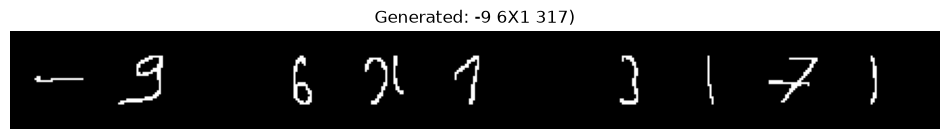

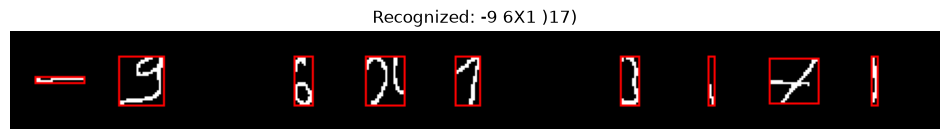

Original:   2(- 6X8 631
Recognized: 2(- 6X8 631
Exact match: True


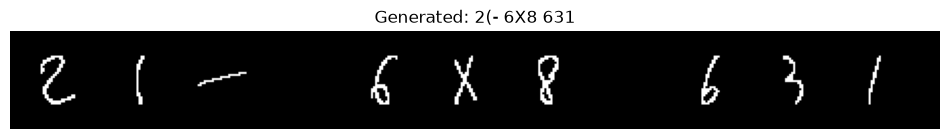

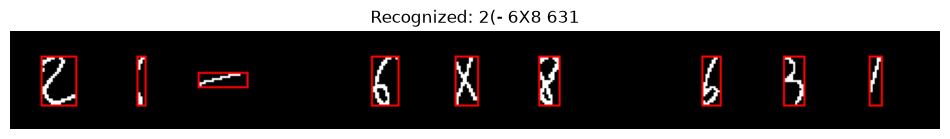

Original:   51)6 +--2 770
Recognized: 51)6 +--2 710
Exact match: False


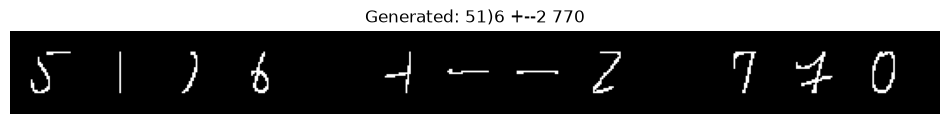

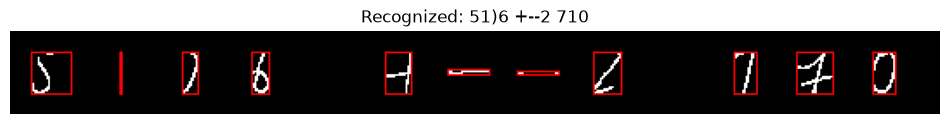

Original:   17- 61 7438
Recognized: 17- 61 +438
Exact match: False


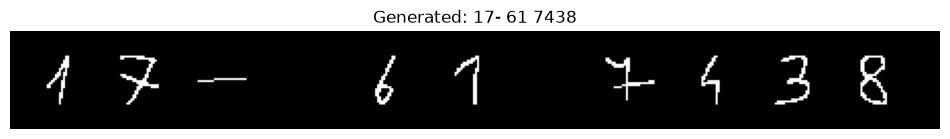

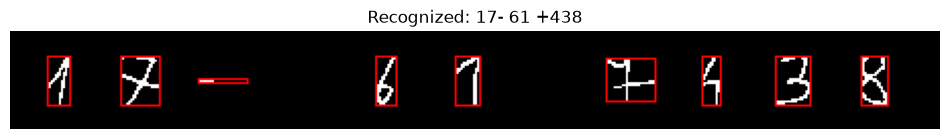

Original:   X6XX (43 92X2
Recognized: X6XX (43 92X2
Exact match: True


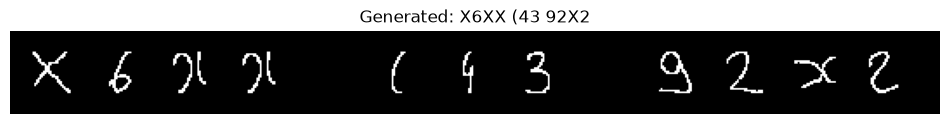

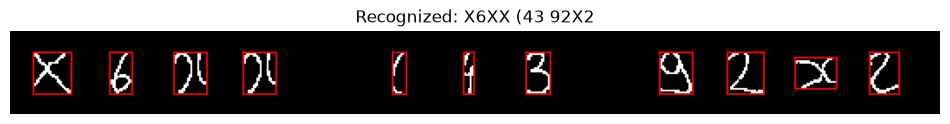

In [8]:
rng = np.random.default_rng(42)
for i in range(5):
    words = []
    for j in range(3):
        length = rng.integers(2, 5)
        words.append(''.join(rng.choice(symbols, size=length)))
    text = ' '.join(words)
    line = generate_line(text, images[test_idx], labels[test_idx], rng)
    result, marked = recognize_line(line, classifier)

    print(f'Original:   {text}')
    print(f'Recognized: {result}')
    print(f'Exact match: {text == result}')
    showpic(line, f'Generated: {text}')
    showpic(marked, f'Recognized: {result}')


## Вывод

Среди проверенных значений лучшим оказалось k = 1: accuracy на валидационной выборке составила 90%, на тестовой — 90,33%.

Из пяти сгенерированных строк две распознаны полностью. В остальных встречаются ошибки отдельных символов: например, 3 распознана как ), а 7 — как 1. Полное совпадение строки требует правильного распознавания всех символов и пробелов, поэтому этот показатель ниже точности классификации отдельных символов.